# Ridge Model (mFRR daily and weekly)

Monthly walk-forward (retrain before each test month on everything already published), one Ridge per
`freq × direction`, inputs from `build_features` (+ `add_model_features`). Four variants against the
previous-known-auction baseline.

- **Validation** : a validation period **before 2025**, used to compare and choose.
- **Evaluation** (from 2025): produced once by `uv run python -m src.models.ridge`.

In [2]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.append("..")

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.linear_model import Ridge

from src.data.data import build_auctions
from src.evaluation import Evaluator
from src.features.build_features import add_model_features, build_features
from src.models.baseline import PreviousKnownAuctionBaseline
from src.models.ridge import FEATURES, model_feature_columns, prepare_auctions, to_contract, walk_forward_ridge

In [3]:
# team auction table (src/data/data.py), daily + weekly, KORR dropped (see prepare_auctions)
auctions_all = prepare_auctions(build_auctions(product="mFRR"), ("daily", "weekly"))
feats = add_model_features(build_features(auctions_all))     # lags + block / day-type one-hots

print("model inputs (all features):", model_feature_columns(feats))
feats.groupby(["freq", "direction"]).size()

model inputs (all features): ['lag1', 'lag2', 'lag3', 'block_00_04', 'block_04_08', 'block_08_12', 'block_12_16', 'block_16_20', 'block_20_24', 'block_week', 'daytype_saturday', 'daytype_sunday_holiday', 'daytype_week', 'daytype_workday']


freq    direction
daily   downwards    17040
        upwards      17034
weekly  downwards      410
        upwards        410
dtype: int64

## 1. Validation period

Share of auctions without a price (no-buy) per year:

In [4]:
a = auctions_all.copy()
a["year"] = a["gc"].dt.year
a.pivot_table(index="year", columns=["freq", "direction"], values="y",
              aggfunc=lambda y: y.isna().mean()).round(2)

freq          daily            weekly        
direction downwards upwards downwards upwards
year                                         
2018           0.00    0.00       NaN     NaN
2019           0.05    0.00       0.0     0.0
2020           0.00    0.06       0.0     0.0
2021           0.11    0.06       0.0     0.0
2022           0.16    0.10       0.0     0.0
2023           0.19    0.12       0.0     0.0
2024           0.90    0.83       0.0     0.0
2025           0.00    0.00       0.0     0.0
2026           0.03    0.00       0.0     0.0

In [5]:
# choose a period before 2025 where the daily auctions have prices 
VAL_START, VAL_LAST_DAY = "2024-01-01", "2024-12-31"
VAL_END = (pd.Timestamp(VAL_LAST_DAY) + pd.Timedelta(days=1)).strftime("%Y-%m-%d")   # exclusive end, for the Evaluator

in_val = (auctions_all["gc"] >= pd.Timestamp(VAL_START, tz="UTC")) & (auctions_all["gc"] < pd.Timestamp(VAL_END, tz="UTC"))
print(VAL_START, "to", VAL_LAST_DAY, ":", in_val.sum(), "auctions,", auctions_all.loc[in_val, "y"].notna().sum(), "with a price")

2024-01-01 to 2024-12-31 : 4120 auctions, 646 with a price


## 2. Variants vs baseline

Target: level **vs** delta

Features: no block and day-type one-hots **vs** with block and day-type one-hots

Groups: one model per frequency x direction **vs** one model per series

In [84]:
variants = {
    "ridge_lags3":                  dict(feature_cols=FEATURES, target="level"),
    "ridge_lags3_delta":            dict(feature_cols=FEATURES, target="delta"),
    "ridge_allfeats_delta":         dict(feature_cols=model_feature_columns(feats), target="delta"),
    "ridge_lags3_delta_per_series": dict(feature_cols=FEATURES, target="delta", group_cols=["series"]),
}

preds_by_variant = {
    name: walk_forward_ridge(feats, start_test=VAL_START, end_test=VAL_LAST_DAY, **kw)
    for name, kw in variants.items()
}

In [86]:
baseline = PreviousKnownAuctionBaseline().fit(auctions_all)
contracts = {"baseline": baseline.predict(auctions_all[in_val])}
contracts.update({name: to_contract(p, name) for name, p in preds_by_variant.items()})

evaluator = Evaluator(actuals=auctions_all, start_test=VAL_START, end_test=VAL_END)
report = evaluator.evaluate_many(contracts)
report.pivot_table(index=["freq", "direction"], columns="model", values="mae").round(3)

model             baseline  ridge_allfeats_delta  ridge_lags3  \
freq   direction                                                
daily  downwards     0.253                 0.243        0.292   
       upwards       0.293                 0.271        0.282   
weekly downwards     0.126                 0.127        0.127   
       upwards       0.046                 0.044        0.046   

model             ridge_lags3_delta  ridge_lags3_delta_per_series  
freq   direction                                                   
daily  downwards              0.292                         0.292  
       upwards                0.282                         0.275  
weekly downwards              0.127                         0.127  
       upwards                0.044                         0.044

## 3. Daily, per block


In [87]:
VARIANT = "ridge_lags3"

p = preds_by_variant[VARIANT]
daily = p[(p["freq"] == "daily") & p["y"].notna()]
by_block = pd.DataFrame({
    "baseline": (daily["pred_baseline"] - daily["y"]).abs().groupby([daily["direction"], daily["series"]]).mean(),
    VARIANT: (daily["pred_ridge"] - daily["y"]).abs().groupby([daily["direction"], daily["series"]]).mean(),
    "n": daily.groupby(["direction", "series"]).size(),
})
by_block.round(3)

baseline  ridge_lags3   n
direction series                                          
downwards daily|downwards|00_04     0.211        0.239  32
          daily|downwards|04_08     0.228        0.271  32
          daily|downwards|08_12     0.311        0.343  32
          daily|downwards|12_16     0.247        0.288  32
          daily|downwards|16_20     0.271        0.317  32
          daily|downwards|20_24     0.247        0.294  32
upwards   daily|upwards|00_04       0.241        0.267  58
          daily|upwards|04_08       0.302        0.281  58
          daily|upwards|08_12       0.336        0.313  58
          daily|upwards|12_16       0.288        0.260  58
          daily|upwards|16_20       0.324        0.326  58
          daily|upwards|20_24       0.264        0.247  58

## 4. Using one series and one month

31 auctions, 7 without a price


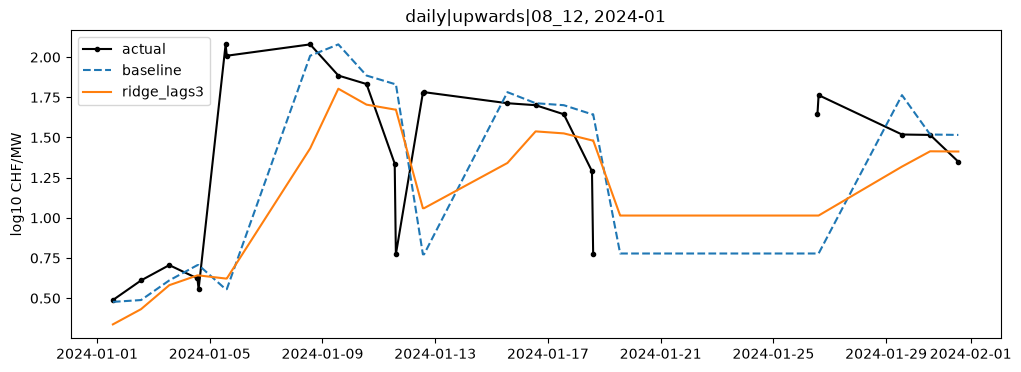

In [88]:
SERIES = "daily|upwards|08_12"
MONTH = VAL_START[:7]         

start = pd.Timestamp(MONTH, tz="UTC")
end = start + pd.offsets.MonthBegin(1)
p = preds_by_variant[VARIANT]
s = p[(p["series"] == SERIES) & (p["gc"] >= start) & (p["gc"] < end)]
print(len(s), "auctions,", s["y"].isna().sum(), "without a price")

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(s["gc"], s["y"], "k.-", label="actual")
ax.plot(s["gc"], s["pred_baseline"], "--", label="baseline")
ax.plot(s["gc"], s["pred_ridge"], "-", label=VARIANT)
ax.set_ylabel("log10 CHF/MW")
ax.set_title(f"{SERIES}, {MONTH}")
ax.legend()
plt.show()

## 5. Weights learned (lags only, level target)

Model trained on everything published before the validation period. 

In [89]:
tr = feats[feats["avail"] < VAL_START].dropna(subset=FEATURES + ["y"])

rows = []
for (freq, direction), d in tr.groupby(["freq", "direction"]):
    m = Ridge(alpha=1.0).fit(d[FEATURES], d["y"])
    rows.append({"freq": freq, "direction": direction, "n_train": len(d),
                 **dict(zip(FEATURES, m.coef_)), "sum_coef": m.coef_.sum(), "intercept": m.intercept_})

pd.DataFrame(rows).round(3)

,freq,direction,n_train,lag1,lag2,lag3,sum_coef,intercept
0,daily,downwards,9810,0.458,0.272,0.192,0.922,0.109
1,daily,upwards,10195,0.469,0.112,0.227,0.808,0.132
2,weekly,downwards,258,0.786,0.197,-0.008,0.974,0.082
3,weekly,upwards,258,0.804,0.092,0.078,0.973,0.070


## 6. Quantiles and bidding

In a pay-as-bid auction you are accepted only if your price is at or below the marginal price,
so bidding too high costs everything and bidding too low only part. `pXX_ridge` is a price the actual
marginal price falls below only XX% of the time.

- **coverage** of [p10, p90]: should be close to 80%;
- **share_rejected**: how often the bid is above the actual price (for p10 it should be close to 10%);

In [90]:
BID_QUANTILES = (0.1, 0.2, 0.3, 0.4, 0.5)
p = walk_forward_ridge(feats, start_test=VAL_START, end_test=VAL_LAST_DAY,
                       quantiles=BID_QUANTILES + (0.9,), **variants[VARIANT])
p = p[p["y"].notna()]
groups = [p["freq"], p["direction"]]

summary = pd.DataFrame({
    "coverage_p10_p90": ((p["y"] >= p["p10_ridge"]) & (p["y"] <= p["p90_ridge"])).groupby(groups).mean(),
    "share_below_p10": (p["y"] < p["p10_ridge"]).groupby(groups).mean(),
})
summary.round(3)

coverage_p10_p90  share_below_p10
freq   direction                                   
daily  downwards             0.839            0.068
       upwards               0.842            0.043
weekly downwards             0.717            0.170
       upwards               0.774            0.132

In [91]:
bids = {"baseline (lag1)": "pred_baseline", "ridge (middle)": "pred_ridge"}
bids.update({f"ridge p{round(100 * q)}": f"p{round(100 * q)}_ridge" for q in BID_QUANTILES})

perfect = (10 ** p["y"]).groupby(groups).sum()
rows = {}
for name, col in bids.items():
    accepted = p[col] <= p["y"]
    revenue = (10 ** p[col]).where(accepted, 0.0)
    rows[(name, "share_rejected")] = (~accepted).groupby(groups).mean()
    rows[(name, "revenue_share")] = revenue.groupby(groups).sum() / perfect

bidding = pd.DataFrame(rows).T
bidding.round(3)

freq                               daily            weekly        
direction                      downwards upwards downwards upwards
baseline (lag1) share_rejected     0.573   0.580     0.774   0.717
                revenue_share      0.444   0.232     0.170   0.276
ridge (middle)  share_rejected     0.484   0.454     0.755   0.755
                revenue_share      0.547   0.364     0.207   0.224
ridge p10       share_rejected     0.068   0.043     0.170   0.132
                revenue_share      0.271   0.179     0.524   0.783
ridge p20       share_rejected     0.161   0.080     0.226   0.151
                revenue_share      0.338   0.270     0.522   0.809
ridge p30       share_rejected     0.245   0.158     0.358   0.283
                revenue_share      0.387   0.326     0.486   0.700
ridge p40       share_rejected     0.318   0.253     0.472   0.358
                revenue_share      0.435   0.359     0.430   0.665
ridge p50       share_rejected     0.448   0.374     0.679   0.566
                revenue_share      0.473   0.367     0.257   0.471

## 7. Final result on the test period (from 2025)

Read from the files written by `uv run python -m src.models.baseline` and `uv run python -m src.models.ridge`.

In [93]:
RESULTS = Path("../results")
files = sorted(RESULTS.glob("metrics_*.parquet"))
if files:
    final = pd.concat([pd.read_parquet(f) for f in files], ignore_index=True)
    display(final.pivot_table(index=["freq", "direction"], columns="model", values="mae").round(3))
else:
    print("no metrics_*.parquet in results/: run the baseline and ridge scripts first")

no metrics_*.parquet in results/: run the baseline and ridge scripts first
